In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import KernelDensity

Insurance Dataset : https://docs.google.com/spreadsheets/d/1dAc3E4U-gBzihJ6HLM2kYVDAqQthdReg20zwwaplTW8/edit?usp=share_link

In [ ]:
df = pd.read_csv('/content/insurance_data.csv')

In [ ]:
# df['age'].info()

df = df.dropna(subset=['age'])

In [ ]:
# df['age'].hasnans

df['age']

,age
0,39.0
1,24.0
7,19.0
8,20.0
9,30.0
...,...
1335,44.0
1336,59.0
1337,30.0
1338,37.0


### Q-1: What is the probability distribution of age in the insurance dataset?

-- Find out using the KDE method

In [ ]:
# code here

# plt.hist(df['age']) -> from here we can infer that histogram does not resides to any of the famous family curves and the col/feature data is
# non-parametric

model = KernelDensity(bandwidth=5, kernel='gaussian')

sample = df['age'].values.reshape((len(df['age']),1))

model.fit(sample)

KernelDensity(bandwidth=5)

In [ ]:
values = np.linspace(sample.min(),sample.max(),1000)
values = values.reshape((len(values),1))

In [ ]:
probabilities = model.score_samples(values)
probabilities = np.exp(probabilities)

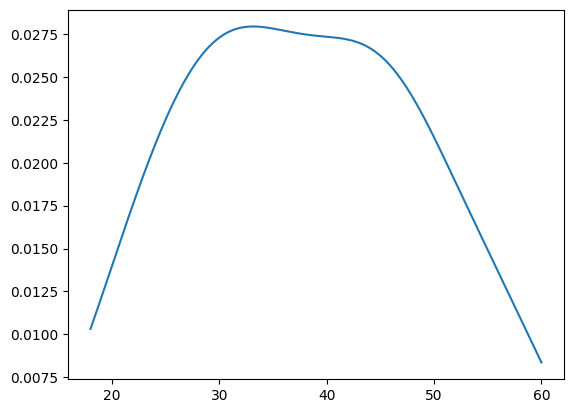

In [ ]:
plt.plot(values,probabilities)
plt.show()

### Q-2: What is the probability of a patient having a BMI greater than 30?

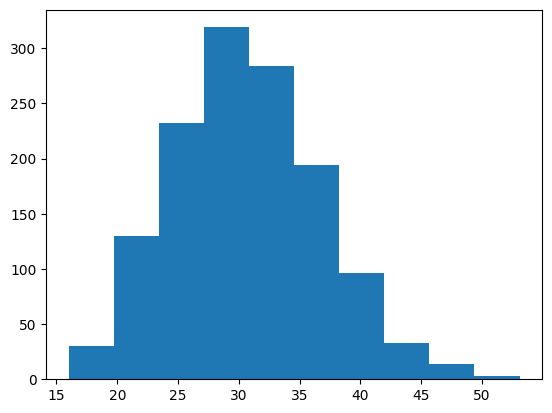

In [ ]:
# answer here

plt.hist(df['bmi'])
# plt.show()

bmi_mean = df['bmi'].mean()
bmi_std_dev = df['bmi'].std()

z = (30 - bmi_mean) / bmi_std_dev
# according to z table value -0.1 and 0.0 there lies 45%
# therefore greater than this will be 100 - 46% -> 54 %

### Q-3: Plot distribution plot of claim for Smoker and non smoker. What changes you see in the plot?

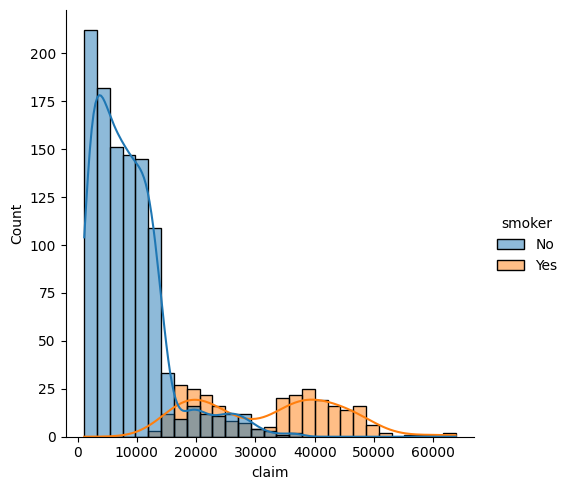

In [ ]:
# code here
sns.displot(data = df, x = 'claim',hue='smoker',kde= True)

# df.head()

### Q-4: Plot the 2D probability density plot of claim and age in the insurance dataset?

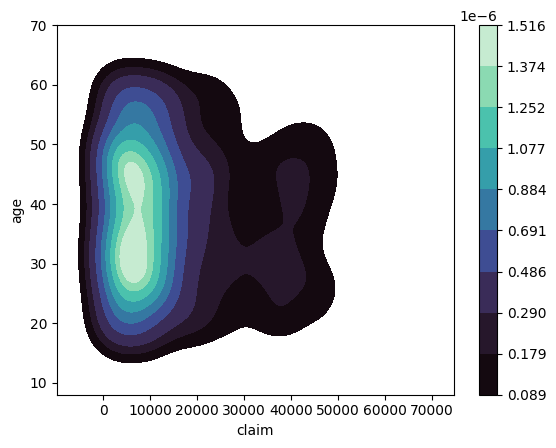

In [ ]:
# code here
sns.kdeplot(data = df, x = 'claim',y = 'age', fill = True, cmap= 'mako', cbar = True)
plt.show()

### Q-5: How does the disribution of claim changes for different region? Plot density plot and note down the observations

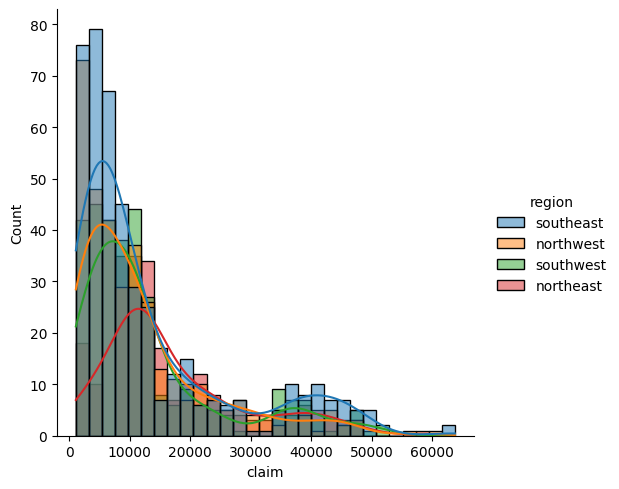

In [ ]:
# code here
df.head()
sns.displot(data = df, x = 'claim', hue = 'region',kde = True)

### Q6: Plot PDF and CDF of claim in insurance data

<Axes: xlabel='claim', ylabel='Proportion'>

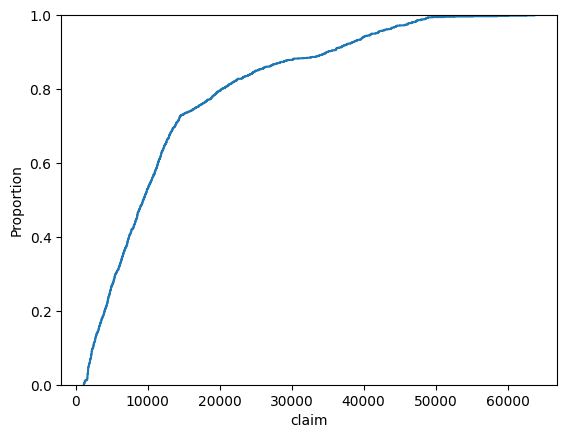

In [ ]:
# code here
# sns.kdeplot(data = df, x = 'claim')
sns.ecdfplot(data = df, x = 'claim')

### Q-7: Given a probability density function f(x) = 2x for 0 <= x <= 1 and f(x) = 0 otherwise, compute the cumulative distribution function F(x) and plot it. Use this to find the probability that X is greater than 0.5.

In [ ]:
x = np.linspace(0,1,1000)
cdf = x ** 2

# plt.plot(x,cdf)
# plt.show()
# cdf at 0.5 is (0.5) ** 2 -> 0.25 but we want greater than therefore 1 - 0.25 -> 0.75

### Q-8: In a manufacturing process, the thickness of a certain material is known to be normally distributed with a mean of 1.2 mm and a standard deviation of 0.05 mm. What is the probability density function of the thickness? Plot the PDF and use it to compute the probability that the thickness is between 1.1 mm and 1.3 mm.

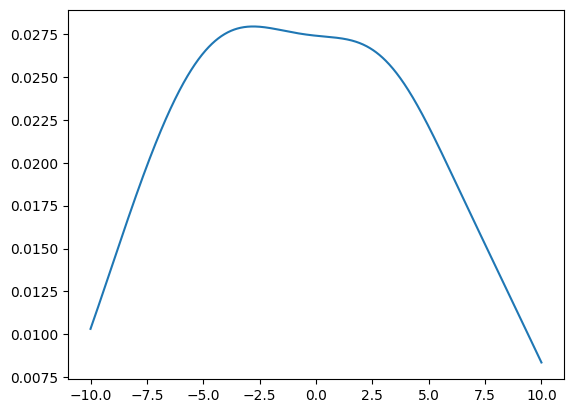

In [ ]:
# answer here
def calPdf(mu,scale,value):
  return ((1/(scale * (2 * 3.14) ** 0.5)) * np.exp(-1/2*((value - mu) / scale) ** 2))

values = np.linspace(-10,10,1000)
probablities = calPdf(1.2,0.05,values)

plt.plot(values,probabilities)

In [ ]:
from scipy.stats import norm
z1 = (1.1 - 1.2) / 0.05
z2 = (1.3 - 1.2) / 0.05

cdf1 = norm.cdf(z1)
cdf2 = norm.cdf(z2)

res = (cdf2 - cdf1) * 100
res

np.float64(95.44997361036415)

### Q-9 : A data scientist is investigating the distribution of customer ages in a retail store. She collects a sample of 100 ages and estimates the probability density function using kernel density estimation. What bandwidth should she choose to obtain the best estimate?

In [ ]:
# answer here
# scott rule => bandwidth(h) = std.dev*n^-(1/5)